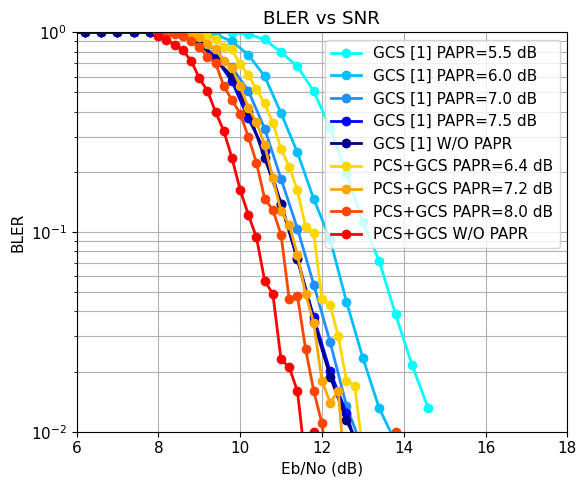

In [23]:
"""
Plot BLER curves from npz files in Experiments_June directory.
Uses matplotlib for visualization.
"""

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import os

# # Set up matplotlib style
# plt.rcParams['figure.figsize'] = (12, 8)
# plt.rcParams['font.size'] = 11
# plt.rcParams['lines.linewidth'] = 2
# plt.rcParams['lines.markersize'] = 6

# Define data directory
data_dir = Path('')

# Load npz files
gcs_data = np.load(data_dir / 'bler_data_gcs_multipath_pn.npz')
pcs_data = np.load(data_dir / 'bler_data_pcs_multipath_pn.npz')

# Extract GCS data
gcs_snr = gcs_data['snr']
gcs_ber = gcs_data['ber']

# Extract PCS data
pcs_snr = pcs_data['snr']
pcs_bler = pcs_data['bler']
pcs_papr = pcs_data['papr']

# =========================
# Plot BLER
# =========================
plt.figure(figsize=(6, 5))

# Requested colours
# GCS colours provided by user (will be cycled if number of curves > colours)
gcs_colors = ['cyan', 'deepskyblue', 'dodgerblue', 'blue', 'darkblue']
# PCS colours
pcs_colors = ['red','gold', 'orange', 'orangered']

PAPR_levels = [5.5, 6.0, 7.0, 7.5, 0.0]
indices_to_plot = [1, 3, 5, 7, 9]

for i, (idx, papr) in enumerate(zip(indices_to_plot, PAPR_levels)):
    color = gcs_colors[i % len(gcs_colors)]
    # Replace label for PAPR==0.0 with 'W/O PAPR'
    if papr == 0.0:
        label = "GCS [1] W/O PAPR"
    else:
        label = f"GCS [1] PAPR={papr} dB"

    plt.semilogy(
        gcs_snr[0],
        gcs_ber[idx],
        marker='o',
        linestyle='-',
        color=color,
        label=label
    )

for idx in [1,2,3,0]:
    color = pcs_colors[idx]
    # Replace label when pcs_papr equals 0.0
    if pcs_papr[idx] == 0.0:
        label = "PCS+GCS W/O PAPR"
    else:
        label = f"PCS+GCS PAPR={pcs_papr[idx]} dB"

    plt.semilogy(
        pcs_snr[idx],
        pcs_bler[idx],
        marker='o',
        linestyle='-',
        color=color,
        label=label,
    )

plt.xlabel("Eb/No (dB)")
plt.ylabel("BLER")
plt.ylim([1e-2, 1])
plt.xlim([6, 18])
plt.title("BLER vs SNR")
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
# plt.savefig(os.path.join(output_folder, "BLER_plot.png"), dpi=300)
# plt.close()
plt.show()


In [8]:
pcs_snr

array([[ 8. ,  8.2,  8.4,  8.6,  8.8,  9. ,  9.2,  9.4,  9.6,  9.8, 10. ,
        10.2, 10.4, 10.6, 10.8, 11. , 11.2, 11.4, 11.6, 11.8, 12. , 12.2,
        12.4, 12.6, 12.8, 13. , 13.2, 13.4, 13.6, 13.8, 14. , 14.2],
       [ 8. ,  8.2,  8.4,  8.6,  8.8,  9. ,  9.2,  9.4,  9.6,  9.8, 10. ,
        10.2, 10.4, 10.6, 10.8, 11. , 11.2, 11.4, 11.6, 11.8, 12. , 12.2,
        12.4, 12.6, 12.8, 13. , 13.2, 13.4, 13.6, 13.8, 14. , 14.2],
       [ 8. ,  8.2,  8.4,  8.6,  8.8,  9. ,  9.2,  9.4,  9.6,  9.8, 10. ,
        10.2, 10.4, 10.6, 10.8, 11. , 11.2, 11.4, 11.6, 11.8, 12. , 12.2,
        12.4, 12.6, 12.8, 13. , 13.2, 13.4, 13.6, 13.8, 14. , 14.2],
       [ 8. ,  8.2,  8.4,  8.6,  8.8,  9. ,  9.2,  9.4,  9.6,  9.8, 10. ,
        10.2, 10.4, 10.6, 10.8, 11. , 11.2, 11.4, 11.6, 11.8, 12. , 12.2,
        12.4, 12.6, 12.8, 13. , 13.2, 13.4, 13.6, 13.8, 14. , 14.2]])